# 01 — Khảo sát dữ liệu cho LSTM Autoencoder

M?i tr??ng b?t bu?c: `D:\LSTM\.venv`, kernel **Python (LSTM .venv)**.
Cell ??u in v? ki?m tra `sys.executable` tr??c khi x? l? d? li?u; kh?ng d?ng `drone_rl`.


## Khảo sát các bộ dữ liệu được gợi ý

| Bộ | Đơn vị chuỗi và nhãn | Split ở nguồn | Đánh giá cho giai đoạn đầu |
|---|---|---|---|
| ECG5000 (UCR/UEA) | 5.000 nhịp tim độc lập, mỗi mẫu 140 bước, 1 biến, 5 lớp | 500 train / 4.500 test | Nhịp được nội suy, lấy ngẫu nhiên từ bản ghi; không nối các hàng để tạo sliding window. Trang nguồn không ánh xạ đầy đủ mã lớp sang tên y khoa; chưa xác minh lớp 1 là normal. |
| NAB | Mỗi CSV là chuỗi đơn biến có timestamp; nhãn sự kiện và khoảng chấm điểm | Giao thức streaming với probation; không có split train/val/cal/test kiểu giám sát cho cặp chọn dưới đây | Chọn để kiểm chứng sliding window; phải tự khai báo split. |
| SMD | 28 máy độc lập, 38 biến; `test_label` chỉ điểm bất thường | Nửa trước train, nửa sau test; từng máy xử lý riêng | Mở rộng đa biến sau; không gộp cửa sổ giữa máy. Train không có nhãn điểm để tự kiểm chứng sạch hoàn toàn. |
| MSL / SMAP | Nhiều kênh telemetry; nhãn khoảng bằng chỉ số trong test | File train/test riêng theo channel | Cần giữ ranh giới channel. Thời gian ẩn danh; nguồn Telemanom công bố đã scale theo min/max test, không thể khẳng định nguyên tắc train-only từ dữ liệu phát hành đó. |

Nguồn sơ cấp: [ECG5000](https://www.timeseriesclassification.com/description.php?Dataset=ECG5000),
[NAB](https://github.com/numenta/NAB),
[SMD — OmniAnomaly](https://github.com/NetManAIOps/OmniAnomaly#data),
[MSL/SMAP — Telemanom](https://github.com/khundman/telemanom#raw-experiment-data).
Không tải và audit ba bộ còn lại trong lượt này; thông tin của chúng là từ tài liệu nguồn,
không phải thống kê tự đo. Tổng kích thước MSL/SMAP giữa các paper/package có thể khác;
không mặc định các bản phát hành có cùng split.

## Bộ chính đề xuất và phạm vi kết luận

Chọn **NAB artificial: `art_daily_small_noise.csv` + `art_daily_jumpsup.csv`** để dựng
pipeline đơn biến nhỏ, có chu kỳ và có nhãn công khai. Đây cũng là cặp trong
[ví dụ Keras](https://keras.io/examples/timeseries/timeseries_anomaly_detection/).
Ví dụ đó dùng convolutional autoencoder; dự án sẽ đề xuất LSTM riêng.

File normal dùng phát triển; file jumpsup dành cho đánh giá cuối. Đây là **hai chuỗi
nhân tạo độc lập**, dù timestamp trùng nhau; không phải hai đoạn liên tiếp của cùng
một hệ thống. Thiết kế phù hợp kiểm tra kỹ thuật, chưa chứng minh khả năng tổng quát
trên ECG, telemetry đa biến hay dữ liệu thực. Cặp train/test này là **lựa chọn thực nghiệm**,
không phải split chính thức của NAB. Không so trực tiếp metric dự án với bảng điểm NAB.

Chính sách được đặt trước huấn luyện: 8 ngày đầu normal cho train, 3 ngày tiếp cho
validation chọn checkpoint, 3 ngày cuối cho calibration ngưỡng. Giữ cả jumpsup cho test.
Notebook này được phép xem phân bố nhãn/biểu đồ test theo yêu cầu audit, nên test
không còn mù với người phân tích; không dùng quan sát đó để tối ưu mô hình/ngưỡng.
Nếu sau này sửa cấu hình theo kết quả test, cần một chuỗi đánh giá mới.

In [1]:
from pathlib import Path
import sys, json, platform
EXPECTED_PYTHON = Path(r'D:\LSTM\.venv\Scripts\python.exe')
print('sys.executable:', sys.executable)
assert Path(sys.executable).resolve() == EXPECTED_PYTHON.resolve(), 'Chon kernel Python (LSTM .venv)'
assert sys.prefix != sys.base_prefix, 'Virtual environment required'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'utils.py').is_file())
sys.path.insert(0, str(ROOT))
from src.utils import (download_nab, load_series, audit_series, NORMAL, TEST,
                       chronological_splits, make_windows, endpoint_mse, normal_threshold)
plt.rcParams.update({'figure.figsize': (12, 3), 'axes.grid': True})
print('Python:', platform.python_version(), '| Project:', ROOT)

sys.executable: D:\LSTM\.venv\Scripts\python.exe


Python: 3.12.10 | Project: D:\LSTM\anomaly-lstm


## Tải, lưu nguồn và xác minh cache

Tải trực tiếp từ commit NAB cố định; lưu URL, SHA-256, số byte, thời điểm tải UTC
trong `data/raw/nab/manifest.json`. Lưu cả README, license và hai loại nhãn nguồn.
Chạy lại dùng cache và kiểm tra hash, không tải đè file chưa có provenance.
`data/raw/` được gitignore; cần giữ manifest cùng dữ liệu khi chuyển máy hoặc chạy lại
để tạo lại dữ liệu từ commit cố định. Hash là kiểm tra toàn vẹn, không phải chứng nhận từ bên thứ ba.

In [2]:
raw, manifest = download_nab(ROOT)
print('Pinned commit:', manifest['commit'])
print('Downloaded UTC:', manifest['downloaded_at_utc'])
display(pd.DataFrame(manifest['files']).T)
normal = load_series(raw, 'normal.csv', NORMAL)
test = load_series(raw, 'test.csv', TEST)
display(normal.head())

Pinned commit: ea702d75cc2258d9d7dd35ca8e5e2539d71f3140
Downloaded UTC: 2026-11-08T12:03:51.030851+00:00


,url,bytes,sha256
normal.csv,https://raw.githubusercontent.com/numenta/NAB/...,140187,c4b304229f69f108eaa024fb2406fcd4510c5c5d95cd00...
test.csv,https://raw.githubusercontent.com/numenta/NAB/...,140548,f79f92b93ee4f9c10e2dc552505e8880b0c618639ed5e0...
combined_windows.json,https://raw.githubusercontent.com/numenta/NAB/...,15359,1e1fbc4601321aad8d0f8b3784c8134299379f68f6c1f7...
combined_labels.json,https://raw.githubusercontent.com/numenta/NAB/...,7015,98724014c162fcfd4be605683517f194051a54e98756c5...
NAB_README.md,https://raw.githubusercontent.com/numenta/NAB/...,12995,418b7afb70dc4550a0a671fd904d1f451ba5aade0ea4de...
NAB_LICENSE.txt,https://raw.githubusercontent.com/numenta/NAB/...,1056,0a0b4d0b10cb1f7ed9ab2993ef93defc03447e6eba9dac...


,timestamp,value,label,source_id,source_row
0,2014-04-01 00:00:00,18.324919,0,artificialNoAnomaly/art_daily_small_noise.csv,0
1,2014-04-01 00:05:00,21.970327,0,artificialNoAnomaly/art_daily_small_noise.csv,1
2,2014-04-01 00:10:00,18.624806,0,artificialNoAnomaly/art_daily_small_noise.csv,2
3,2014-04-01 00:15:00,21.953684,0,artificialNoAnomaly/art_daily_small_noise.csv,3
4,2014-04-01 00:20:00,21.909120,0,artificialNoAnomaly/art_daily_small_noise.csv,4


## Diễn giải nhãn

`combined_labels.json` lưu thời điểm sự kiện. `combined_windows.json` lưu khoảng
chấm điểm quanh sự kiện, được tạo bởi [NAB labeler](https://github.com/numenta/NAB/blob/master/nab/labeler.py).
Khoảng này có dung sai phát hiện sớm/muộn, **không đồng nghĩa mọi điểm trong đó đều
có tín hiệu vật lý bất thường**. Không suy nhãn từ biên độ hay tự cắt vùng nhảy.

Quy ước dự án: nhãn điểm = 1 khi timestamp nằm trong khoảng nguồn, bao gồm hai đầu;
ngoài khoảng = 0. Vì vậy metric điểm sau này chỉ đo sự phù hợp với khoảng NAB đã chuyển đổi.
Không gọi đây là NAB score: chưa triển khai trọng số thời điểm, probation và chuẩn hóa
của benchmark. File normal có danh sách khoảng rỗng; đây là chuỗi nhân tạo được nguồn
xác định không có bất thường, khác với việc đoán train sạch vì không có nhãn.

In [3]:
intervals = json.loads((raw / 'combined_windows.json').read_text())
events = json.loads((raw / 'combined_labels.json').read_text())
for source in [NORMAL, TEST]:
    print(source, '\n  intervals:', intervals[source], '\n  events:', events[source])
assert intervals[NORMAL] == []
assert set(normal.label.unique()) == {0}
assert set(test.label.unique()) == {0, 1}
# Independent check of inclusive endpoints, against raw timestamps.
expected = np.zeros(len(test), dtype=bool)
for start, end in intervals[TEST]:
    expected |= ((test.timestamp >= pd.Timestamp(start)) & (test.timestamp <= pd.Timestamp(end))).to_numpy()
np.testing.assert_array_equal(test.label.to_numpy(), expected.astype(np.int8))
for event in events[TEST]:
    assert test.loc[test.timestamp.eq(pd.Timestamp(event)), 'label'].eq(1).all()
display(pd.crosstab(test.label, columns='count').rename(index={0: 'outside_interval', 1: 'inside_interval'}))

artificialNoAnomaly/art_daily_small_noise.csv 
  intervals: [] 
  events: []
artificialWithAnomaly/art_daily_jumpsup.csv 
  intervals: [['2014-04-10 16:15:00.000000', '2014-04-12 01:45:00.000000']] 
  events: ['2014-04-11 09:00:00']


col_0,count
label,
outside_interval,3629
inside_interval,403


In [4]:
audit = pd.DataFrame({'normal_source': audit_series(normal), 'test_source': audit_series(test)}).T
display(audit)
display(pd.concat({'normal': normal.value.describe(), 'test': test.value.describe()}, axis=1))
cross_duplicates = len(normal.merge(test, on=['timestamp', 'value']))
shared_timestamps = len(set(normal.timestamp) & set(test.timestamp))
print('Cross-source identical (timestamp, value):', cross_duplicates)
print('Shared timestamp count (independent sources):', shared_timestamps)
for frame in [normal, test]:
    stats = audit_series(frame)
    assert stats['rows'] == 4032
    assert stats['ordered']
    assert all(stats[k] == 0 for k in ['missing_cells', 'nonfinite_values', 'duplicate_rows',
                                      'duplicate_timestamps', 'non_5min_gaps'])
assert cross_duplicates == 0
print('PASS: schema, finite values, label domain, timestamps, cadence and duplicates')

,rows,features,normal,anomaly,missing_cells,nonfinite_values,duplicate_rows,duplicate_timestamps,repeated_values,ordered,non_5min_gaps,start,end
normal_source,4032,1,4032,0,0,0,0,0,0,True,0,2014-04-01 00:00:00,2014-04-14 23:55:00
test_source,4032,1,3629,403,0,0,0,0,0,True,0,2014-04-01 00:00:00,2014-04-14 23:55:00


,normal,test
count,4032.000000,4032.000000
mean,42.438353,44.494254
std,28.077122,32.432473
min,18.000964,18.001010
25%,19.841390,19.991382
50%,21.608487,21.648503
75%,75.450282,76.435943
max,87.976128,164.947481


Cross-source identical (timestamp, value): 0
Shared timestamp count (independent sources): 4032
PASS: schema, finite values, label domain, timestamps, cadence and duplicates


Giữ thứ tự gốc, không sort để che lỗi đầu vào. Kiểm tra cả bản ghi trùng,
timestamp trùng, giá trị lặp và bản ghi trùng xuyên hai nguồn. Giá trị lặp tự nó
không phải lỗi và không được xóa. Timestamp không có timezone ở nguồn; không gán
múi giờ địa phương. Nếu có missing/gap trong lần thay dữ liệu, dừng để review;
giai đoạn này không impute hoặc nối qua khoảng trống.

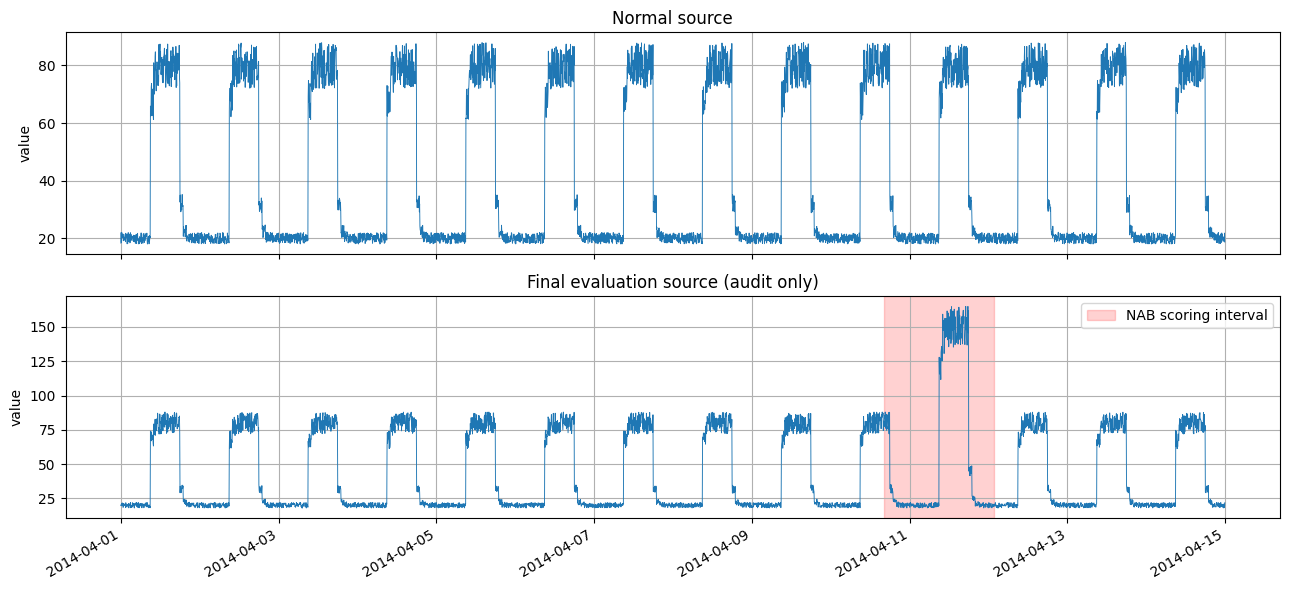

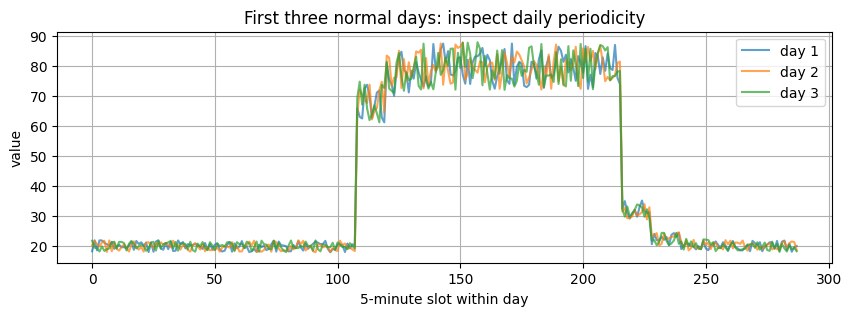

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, frame, title in zip(axes, [normal, test], ['Normal source', 'Final evaluation source (audit only)']):
    ax.plot(frame.timestamp, frame.value, linewidth=0.65)
    for start, end in intervals[frame.source_id.iloc[0]]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='red', alpha=.18, label='NAB scoring interval')
    ax.set(title=title, ylabel='value')
    if frame.label.any(): ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
for day in range(3):
    ax.plot(np.arange(288), normal.value.iloc[day*288:(day+1)*288], alpha=.7, label=f'day {day+1}')
ax.set(title='First three normal days: inspect daily periodicity', xlabel='5-minute slot within day', ylabel='value')
ax.legend()
plt.show()

In [6]:
result = {
    'dataset': 'NAB artificial pair', 'commit': manifest['commit'],
    'audit': {k: audit_series(v) for k, v in [('normal', normal), ('test', test)]},
    'shared_timestamps': shared_timestamps, 'cross_source_duplicate_records': cross_duplicates,
    'label_policy': 'inclusive combined_windows intervals; not physical point ground truth',
    'checks_passed': ['schema', 'label domain and inclusive intervals', 'finite values',
                      'strict timestamps and 5-minute cadence', 'within/cross-source duplicates'],
    'limitations': ['No requirement image received', 'Only chosen NAB pair downloaded',
                    'Synthetic independent sources, not an official supervised split',
                    'Test inspected for audit; no training or threshold fitting'],
}
(ROOT / 'results').mkdir(exist_ok=True)
(ROOT / 'results' / 'data_audit.json').write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved results/data_audit.json')

Saved results/data_audit.json


## Đọc các tham khảo mô hình và phần chưa kiểm chứng

[EncDec-AD (2016), mục 2](https://arxiv.org/html/1607.00148v2): học tái tạo normal;
bài gốc dùng tái tạo đảo chiều và mô hình hóa vector lỗi. Cấu hình đơn giản ở notebook 02
là biến thể của dự án, không phải tái lập nguyên bản.

[TranAD (2022)](https://arxiv.org/html/2201.07284v6) dùng Transformer, self-conditioning
và huấn luyện đối kháng; [repo](https://github.com/imperial-qore/TranAD) tự lưu ý các
baseline trong repo có thể khác bản dùng trong paper. UCR trong bảng TranAD là benchmark
anomaly detection, không đồng nhất với ECG5000 classification.

[Anomaly Transformer (2022)](https://arxiv.org/html/2110.02642v5) dùng association
discrepancy và minimax. Đã xem [loader](https://github.com/thuml/Anomaly-Transformer/blob/main/data_factory/data_loader.py)
và [solver](https://github.com/thuml/Anomaly-Transformer/blob/main/solver.py): có loader
đặt validation bằng test; không sao chép giao thức đó vào dự án này. Chưa chạy code
Transformer hoặc kiểm chứng các con số paper.

Đã đọc các trang/mục liên quan trực tuyến; chỉ tải snapshot dữ liệu và tài liệu NAB
được liệt kê trong manifest. `NAB/labels/README.md` trả 404, wiki `Anomaly-Labels`
không có nội dung mô tả; thay bằng JSON và mã labeler sơ cấp. Chưa xác minh ý nghĩa
y khoa từng mã ECG5000, chất lượng toàn bộ SMD/MSL/SMAP hoặc ảnh yêu cầu của cô.